<center><h1>Last_First_HW4</h1></center>
<br>
<br>

Name: Anita Hovsepian
<br>
Github Username: anitahov
<br>
USC ID: 6881664760

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, zipfile, re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, roc_curve, auc, roc_auc_score)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE=42


Get the AReM Data Set

In [5]:

# Import libraries
from pathlib import Path
import zipfile
import requests
import pandas as pd
import re

# Dataset location on GitHub
url = "https://raw.githubusercontent.com/anitahov/Hovsepian_Anita_HW4/main/AReM.zip"

root = Path("AReM")
archive = Path("AReM.zip")

# Download the dataset if needed
if not archive.exists() and not (root / "bending1").exists():
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    archive.write_bytes(response.content)

# Extract the ZIP file
if not (root / "bending1").exists():
    with zipfile.ZipFile(archive, "r") as z:
        z.extractall(".")

# Find the extracted dataset folder
if not (root / "bending1").exists():
    folders = list(Path(".").rglob("bending1"))
    if folders:
        root = folders[0].parent

assert (root / "bending1").exists(), "Dataset folder not found."

print("Dataset successfully loaded from:", root)

# List of activities
activities = [
    'bending1', 'bending2', 'cycling',
    'lying', 'sitting', 'standing', 'walking'
]

# Sensor measurement columns
columns = [
    'time', 'avg_rss12', 'var_rss12',
    'avg_rss13', 'var_rss13',
    'avg_rss23', 'var_rss23'
]

sensor_cols = columns[1:]

# Store all recordings
records = []

# Read data from each activity folder
for activity in activities:
    folder = root / activity

    # Read CSV files in numerical order
    files = sorted(
        folder.glob('dataset*.csv'),
        key=lambda p: int(
            re.search(r'dataset(\d+)', p.name).group(1)
        )
    )

    for path in files:
        rows = []

        # Read each line of the CSV file
        for line in path.read_text(errors='replace').splitlines():

            # Skip comments and empty lines
            if line.startswith('#') or not line.strip():
                continue

            # Separate values by commas or spaces
            vals = re.split(r'[,\s]+', line.strip().strip(','))

            # Keep rows with seven numeric values
            if len(vals) == 7:
                try:
                    rows.append([float(x) for x in vals])
                except ValueError:
                    continue

        # Convert data into a DataFrame
        df = pd.DataFrame(rows, columns=columns)

        # Check for empty files
        if df.empty:
            raise ValueError(f"No data found in {path}")

        # Save recording information
        records.append({
            'activity': activity,
            'file': path.name,
            'number': int(
                re.search(r'dataset(\d+)', path.name).group(1)
            ),
            'data': df
        })

# Check that all recordings were loaded
print("Total recordings:", len(records))
assert len(records) == 88, "Expected 88 recordings."

print("Dataset is ready for analysis!")



Dataset successfully loaded from: AReM
Total recordings: 88
Dataset is ready for analysis!


### (b) Splitting Data

In [6]:

# Split recordings into training and testing sets
for r in records:

    # Use the first 2 bending recordings for testing
    # Use the first 3 recordings of other activities for testing
    if r['activity'].startswith('bending'):
        r['split'] = 'test' if r['number'] <= 2 else 'train'
    else:
        r['split'] = 'test' if r['number'] <= 3 else 'train'

# Count recordings in each group
activity_labels = pd.Series(
    [r['activity'] for r in records],
    name='Activity'
)

split_labels = pd.Series(
    [r['split'] for r in records],
    name='Split'
)

# Display training and testing counts
print(pd.crosstab(activity_labels, split_labels))


Split     test  train
Activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12


### (c) Feature Extraction

In [7]:
# Extract min, max, mean, median, standard deviation, first and third quartiles
# for each of six sensor time series: 42 features per recording.
stats=['min','max','mean','median','std','q1','q3']
def summarize(df):
    d={}
    for col in sensor_cols:
        s=df[col]
        d.update({f'{col}_min':s.min(),f'{col}_max':s.max(),f'{col}_mean':s.mean(),
                  f'{col}_median':s.median(),f'{col}_std':s.std(ddof=1),
                  f'{col}_q1':s.quantile(.25),f'{col}_q3':s.quantile(.75)})
    return d
features=pd.DataFrame([{'activity':r['activity'],'file':r['file'],'split':r['split'],**summarize(r['data'])} for r in records])
feature_cols=[c for c in features if c not in ['activity','file','split']]
train=features[features.split=='train'].copy(); test=features[features.split=='test'].copy()
display(features.head());print('Training:',train.shape,'Test:',test.shape)
print('Feature standard deviations across training instances:')
display(train[feature_cols].std().sort_values(ascending=False).to_frame('std').head(12))
print('Three potentially informative features: avg_rss12_mean, avg_rss12_std, avg_rss13_mean.')


,activity,file,split,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,avg_rss12_q3,...,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1,dataset1.csv,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Training: (69, 45) Test: (19, 45)
Feature standard deviations across training instances:


,std
avg_rss12_min,8.794295
avg_rss12_q1,5.731262
avg_rss23_q1,5.543882
avg_rss23_max,5.449726
avg_rss23_min,5.368786
avg_rss23_median,5.267414
var_rss12_max,5.147841
avg_rss23_mean,5.120513
avg_rss23_q3,4.957231
avg_rss12_median,4.956111


Three potentially informative features: avg_rss12_mean, avg_rss12_std, avg_rss13_mean.


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

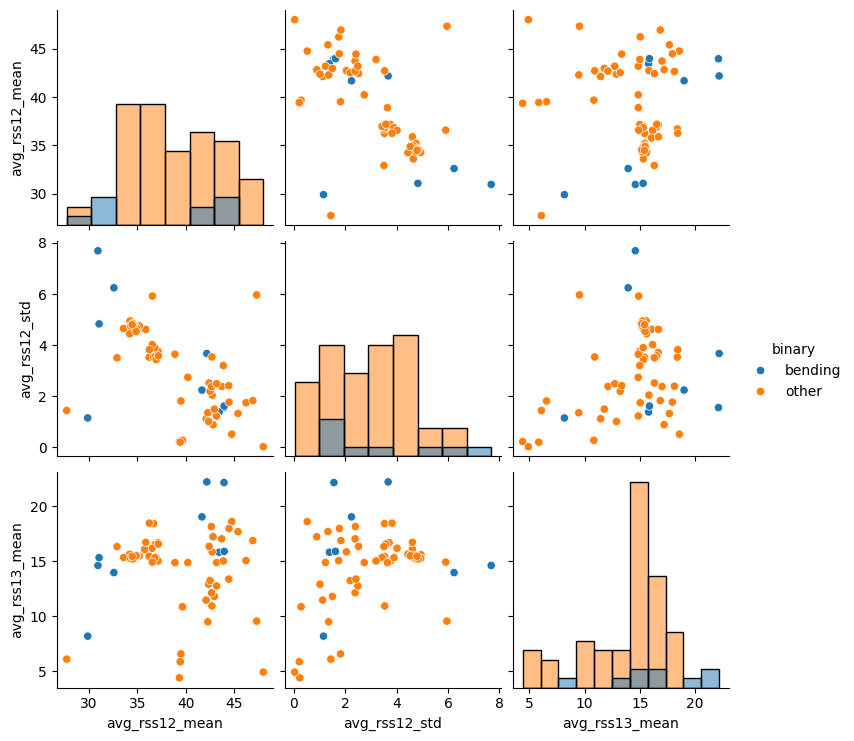

In [9]:

# Import libraries for plotting
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select three features for comparison
plot_features = [
    'avg_rss12_mean',
    'avg_rss12_std',
    'avg_rss13_mean'
]

# Label activities as bending or other
plot_df = train.copy()

plot_df['binary'] = np.where(
    plot_df['activity'].str.startswith('bending'),
    'bending',
    'other'
)

# Create scatterplots to compare activities
sns.pairplot(
    plot_df[plot_features + ['binary']],
    hue='binary',
    diag_kind='hist'
)

# Display the plots
plt.show()


#### ii. Splitted Plots

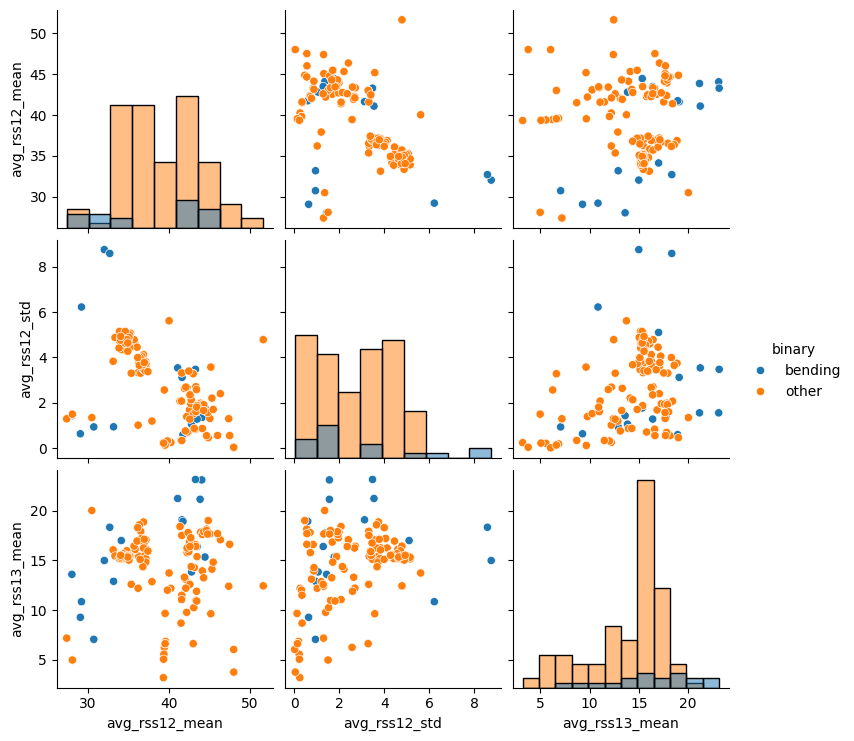

In [10]:
# Split each recording into two equal contiguous segments, then compare scatterplots.
def segmented_table(items,segments):
    out=[]
    for r in items:
        for j,ind in enumerate(np.array_split(np.arange(len(r['data'])),segments),1):
            out.append({'activity':r['activity'],'file':r['file'],'segment':j,
                        **summarize(r['data'].iloc[ind])})
    return pd.DataFrame(out)
seg2=segmented_table([r for r in records if r['split']=='train'],2)
seg2['binary']=np.where(seg2.activity.str.startswith('bending'),'bending','other')
sns.pairplot(seg2[plot_features+['binary']],hue='binary',diag_kind='hist')
plt.show()


#### iii. Time Series Segments

In [12]:
# Choose number of time segments by 5-fold stratified CV on training recordings.
# Scale *within* each fold and select number of features through L1 regularization.

# Import libraries for classification
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Set random state for consistent results
RANDOM_STATE = 42

train_records=[r for r in records if r['split']=='train']
test_records=[r for r in records if r['split']=='test']
def dataset_for_segments(items,L):
    rows=[]
    for r in items:
        row={}
        for j,inds in enumerate(np.array_split(np.arange(len(r['data'])),L),1):
            row.update({f's{j}_{k}':v for k,v in summarize(r['data'].iloc[inds]).items()})
        rows.append(row)
    return pd.DataFrame(rows)
y_bin=np.array([int(r['activity'].startswith('bending')) for r in train_records])
y_bin_test=np.array([int(r['activity'].startswith('bending')) for r in test_records])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
# A small regularization grid keeps this notebook practical to rerun.
Cs=[0.01,0.1,1,10,100]
results=[]
for L in range(1,21):
    X=dataset_for_segments(train_records,L)
    model=GridSearchCV(Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',solver='liblinear',max_iter=5000,random_state=RANDOM_STATE))]),
                       {'clf__C':Cs},cv=cv,scoring='accuracy',n_jobs=-1)
    model.fit(X,y_bin)
    results.append((L,model.best_score_,model.best_params_['clf__C']))
segment_scores=pd.DataFrame(results,columns=['L','cv_accuracy','C'])
display(segment_scores)
best_L=int(segment_scores.sort_values(['cv_accuracy','L'],ascending=[False,True]).iloc[0]['L'])
print('Best segment count:',best_L)


,L,cv_accuracy,C
0,1,0.957143,1
1,2,0.957143,1
2,3,0.957143,1
3,4,0.957143,1
4,5,0.927473,10
5,6,0.957143,100
6,7,0.927473,1
7,8,0.928571,1
8,9,0.927473,1
9,10,0.971429,100


Best segment count: 19


#### iv. Confusion Matrix

Out-of-fold training confusion matrix:


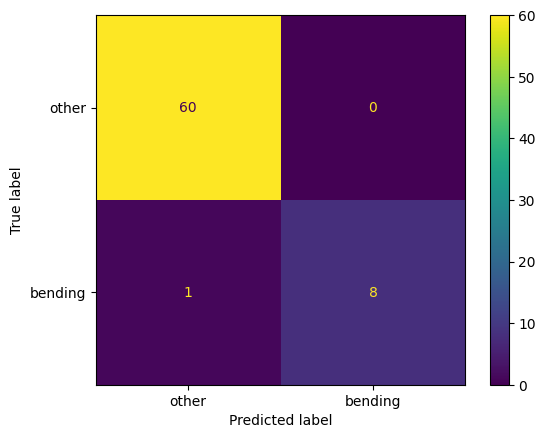

              precision    recall  f1-score   support

       other       0.98      1.00      0.99        60
     bending       1.00      0.89      0.94         9

    accuracy                           0.99        69
   macro avg       0.99      0.94      0.97        69
weighted avg       0.99      0.99      0.99        69



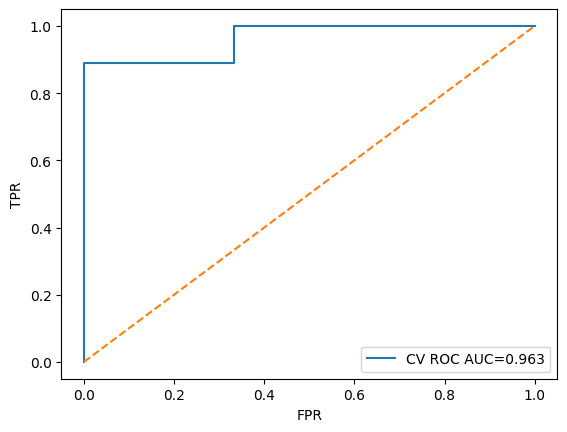

Selected nonzero coefficients: 10


In [14]:

# Import tools for model evaluation
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# Import plotting library
import matplotlib.pyplot as plt

X_train=dataset_for_segments(train_records,best_L)
X_test=dataset_for_segments(test_records,best_L)
binary_model=GridSearchCV(Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',solver='liblinear',max_iter=5000,random_state=RANDOM_STATE))]),
 {'clf__C':Cs},cv=cv,scoring='accuracy',n_jobs=-1).fit(X_train,y_bin)
selected_C=binary_model.best_params_['clf__C']
base=Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',C=selected_C,solver='liblinear',max_iter=5000,random_state=RANDOM_STATE))])
oof=cross_val_predict(base,X_train,y_bin,cv=cv,method='predict')
oof_prob=cross_val_predict(base,X_train,y_bin,cv=cv,method='predict_proba')[:,1]
print('Out-of-fold training confusion matrix:')
ConfusionMatrixDisplay.from_predictions(y_bin,oof,display_labels=['other','bending']);plt.show()
print(classification_report(y_bin,oof,target_names=['other','bending']))
fpr,tpr,_=roc_curve(y_bin,oof_prob)
plt.plot(fpr,tpr,label=f'CV ROC AUC={auc(fpr,tpr):.3f}');plt.plot([0,1],[0,1],'--');plt.xlabel('FPR');plt.ylabel('TPR');plt.legend();plt.show()
print('Selected nonzero coefficients:',np.count_nonzero(binary_model.best_estimator_.named_steps['clf'].coef_))


#### v. Test Classifier

Held-out test accuracy: 0.9473684210526315
Held-out test ROC AUC: 0.9833333333333334
              precision    recall  f1-score   support

       other       0.94      1.00      0.97        15
     bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19



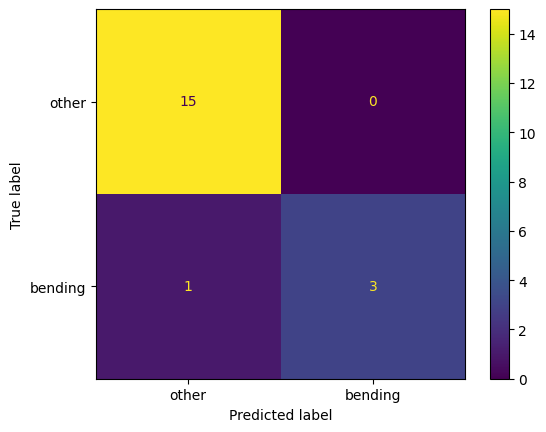

In [17]:


# Import tools for evaluating the classifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict activities using the trained model
pred = binary_model.predict(X_test)

# Get prediction probabilities
prob = binary_model.predict_proba(X_test)[:, 1]

# Calculate test accuracy
print("Held-out test accuracy:",
      accuracy_score(y_bin_test, pred))

# Calculate ROC AUC score
print("Held-out test ROC AUC:",
      roc_auc_score(y_bin_test, prob))

# Display classification results
print(classification_report(
    y_bin_test,
    pred,
    target_names=['other', 'bending']
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_bin_test,
    pred,
    display_labels=['other', 'bending']
)

plt.show()


#### vi. Separation

**Separation.** Complete or quasi-complete separation occurs when a linear combination of predictors perfectly (or nearly perfectly) divides the classes. Unpenalized logistic regression can then have unstable or diverging coefficient estimates. L1 regularization constrains coefficients and mitigates this issue; check the fitted coefficient magnitudes, convergence, and cross-validated performance rather than claiming separation solely from a plot.

#### vii. Imbalance

In [19]:
print('Training class balance (0=other, 1=bending):',dict(zip(*np.unique(y_bin,return_counts=True))))
print('Test class balance:',dict(zip(*np.unique(y_bin_test,return_counts=True))))
# Compare a class-weighted logistic model using the same held-out split.
weighted=GridSearchCV(Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',solver='liblinear',class_weight='balanced',max_iter=5000,random_state=RANDOM_STATE))]),
 {'clf__C':Cs},cv=cv,scoring='balanced_accuracy',n_jobs=-1).fit(X_train,y_bin)
print('Balanced model test report:')
print(classification_report(y_bin_test,weighted.predict(X_test),target_names=['other','bending']))


Training class balance (0=other, 1=bending): {np.int64(0): np.int64(60), np.int64(1): np.int64(9)}
Test class balance: {np.int64(0): np.int64(15), np.int64(1): np.int64(4)}
Balanced model test report:
              precision    recall  f1-score   support

       other       0.94      1.00      0.97        15
     bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19



### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [20]:
# Jointly choose the segment count and L1 regularization parameter via CV.
# This is the preferred sparse alternative to manual predictor selection.
l1_results=[]
for L in range(1,21):
    X=dataset_for_segments(train_records,L)
    search=GridSearchCV(Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',solver='liblinear',max_iter=5000,random_state=RANDOM_STATE))]),
      {'clf__C':Cs},cv=cv,scoring='accuracy',n_jobs=-1).fit(X,y_bin)
    l1_results.append((L,search.best_params_['clf__C'],search.best_score_))
l1_table=pd.DataFrame(l1_results,columns=['segments','C','cv_accuracy'])
display(l1_table)
best_row=l1_table.sort_values(['cv_accuracy','segments'],ascending=[False,True]).iloc[0]
L_l1=int(best_row.segments)
Xtr_l1=dataset_for_segments(train_records,L_l1)
Xte_l1=dataset_for_segments(test_records,L_l1)
l1_model=Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(penalty='l1',C=float(best_row.C),solver='liblinear',max_iter=5000,random_state=RANDOM_STATE))]).fit(Xtr_l1,y_bin)
print('L1 test accuracy:',accuracy_score(y_bin_test,l1_model.predict(Xte_l1)))
print('Selected features:',Xtr_l1.columns[l1_model.named_steps['clf'].coef_.ravel()!=0].tolist())


,segments,C,cv_accuracy
0,1,1,0.957143
1,2,1,0.957143
2,3,1,0.957143
3,4,1,0.957143
4,5,10,0.927473
5,6,100,0.957143
6,7,1,0.927473
7,8,1,0.928571
8,9,1,0.927473
9,10,100,0.971429


L1 test accuracy: 0.9473684210526315
Selected features: ['s2_avg_rss23_min', 's3_avg_rss23_min', 's3_avg_rss23_q1', 's5_avg_rss23_max', 's11_avg_rss12_max', 's14_var_rss13_std', 's15_var_rss23_std', 's17_avg_rss23_min', 's18_avg_rss23_std', 's18_var_rss23_max']


#### ii. Comparison


Both binary logistic regression approaches achieved a test accuracy of 94.74%. The L1-penalized model selected 10 important features, which helps reduce the number of predictors used for classification. Both implementations use L1 regularization, so their results are very similar. Overall, L1 regularization helps simplify the model while maintaining strong classification performance.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Finished L=1/20
Finished L=2/20
Finished L=3/20
Finished L=4/20
Finished L=5/20
Finished L=6/20
Finished L=7/20
Finished L=8/20
Finished L=9/20
Finished L=10/20
Finished L=11/20
Finished L=12/20
Finished L=13/20
Finished L=14/20
Finished L=15/20
Finished L=16/20
Finished L=17/20
Finished L=18/20
Finished L=19/20
Finished L=20/20


,segments,C,cv_accuracy
0,1,0.1,0.883987
1,2,1.0,0.897876
2,3,10.0,0.883170
3,4,1.0,0.869281
4,5,10.0,0.883987
5,6,10.0,0.913399
6,7,1.0,0.854575
7,8,10.0,0.854575
8,9,1.0,0.870098
9,10,10.0,0.854575


Best segments: 6
Best C: 10.0
Best CV accuracy: 0.9133986928104576
Multiclass test accuracy: 0.8947368421052632
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.88      0.89        19
weighted avg       0.94      0.89      0.89        19



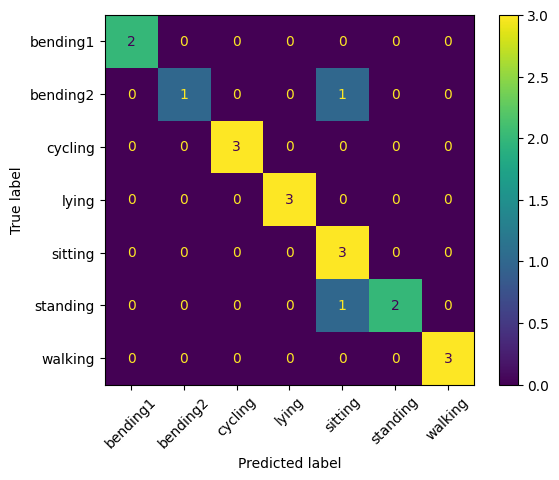

In [26]:

# Import classification libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Keep all seven activity classes
y_multi = np.array([r['activity'] for r in train_records])
y_multi_test = np.array([r['activity'] for r in test_records])

# Use 4 folds because the smallest class has 4 training recordings
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Create a multinomial logistic regression model
def make_multi_model(C=1.0):
    return Pipeline([
        ('scale', StandardScaler()),
        ('clf', LogisticRegression(
            C=C,
            solver='lbfgs',
            max_iter=2000,
            random_state=42
        ))
    ])

# Test different numbers of segments
multi_results = []

for L in range(1, 21):

    # Extract statistical features
    X = dataset_for_segments(train_records, L)

    # Select regularization using cross-validation
    search = GridSearchCV(
        make_multi_model(),
        {'clf__C': [0.1, 1, 10]},
        cv=cv_multi,
        scoring='accuracy',
        n_jobs=-1
    )

    search.fit(X, y_multi)

    # Save cross-validation results
    multi_results.append([
        L,
        search.best_params_['clf__C'],
        search.best_score_
    ])

    print(f"Finished L={L}/20", flush=True)

# Display results
multitable = pd.DataFrame(
    multi_results,
    columns=['segments', 'C', 'cv_accuracy']
)

display(multitable)

# Find the best segment count and C
best = multitable.sort_values(
    ['cv_accuracy', 'segments'],
    ascending=[False, True]
).iloc[0]

L_multi = int(best['segments'])
best_C = float(best['C'])

print("Best segments:", L_multi)
print("Best C:", best_C)
print("Best CV accuracy:", best['cv_accuracy'])

# Prepare training and testing data
Xm = dataset_for_segments(train_records, L_multi)
Xmt = dataset_for_segments(test_records, L_multi)

# Train the final model
multi_model = make_multi_model(best_C)
multi_model.fit(Xm, y_multi)

# Predict test activities
multi_pred = multi_model.predict(Xmt)

# Display test accuracy and classification report
multi_test_accuracy = accuracy_score(y_multi_test, multi_pred)

print("Multiclass test accuracy:", multi_test_accuracy)
print(classification_report(
    y_multi_test,
    multi_pred,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_multi_test,
    multi_pred,
    xticks_rotation=45
)

plt.show()



#### ii. Naive Bayes

Finished L=1/20
Finished L=2/20
Finished L=3/20
Finished L=4/20
Finished L=5/20
Finished L=6/20
Finished L=7/20
Finished L=8/20
Finished L=9/20
Finished L=10/20
Finished L=11/20
Finished L=12/20
Finished L=13/20
Finished L=14/20
Finished L=15/20
Finished L=16/20
Finished L=17/20
Finished L=18/20
Finished L=19/20
Finished L=20/20


,model,segments,cv_accuracy,parameters
0,Gaussian,1,0.870915,{'nb__var_smoothing': 1e-05}
19,Multinomial,10,0.855392,{'nb__alpha': 0.01}
33,Multinomial,17,0.841503,{'nb__alpha': 0.01}
1,Multinomial,1,0.841503,{'nb__alpha': 0.01}
3,Multinomial,2,0.828431,{'nb__alpha': 0.1}
31,Multinomial,16,0.826797,{'nb__alpha': 0.01}
2,Gaussian,2,0.825980,{'nb__var_smoothing': 1e-09}
39,Multinomial,20,0.812908,{'nb__alpha': 0.01}
37,Multinomial,19,0.812092,{'nb__alpha': 0.01}
25,Multinomial,13,0.811275,{'nb__alpha': 0.1}



Model: Gaussian
Best segments: 1
CV accuracy: 0.8709150326797386
Test accuracy: 0.8947368421052632
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.90      0.91        19
weighted avg       0.94      0.89      0.90        19



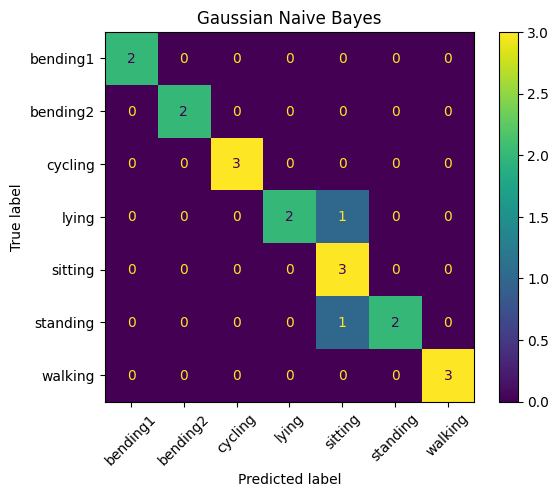


Model: Multinomial
Best segments: 10
CV accuracy: 0.8553921568627451
Test accuracy: 0.7894736842105263
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       0.75      1.00      0.86         3
       lying       0.67      0.67      0.67         3
     sitting       0.67      0.67      0.67         3
    standing       0.50      0.33      0.40         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.79        19
   macro avg       0.80      0.81      0.80        19
weighted avg       0.78      0.79      0.78        19



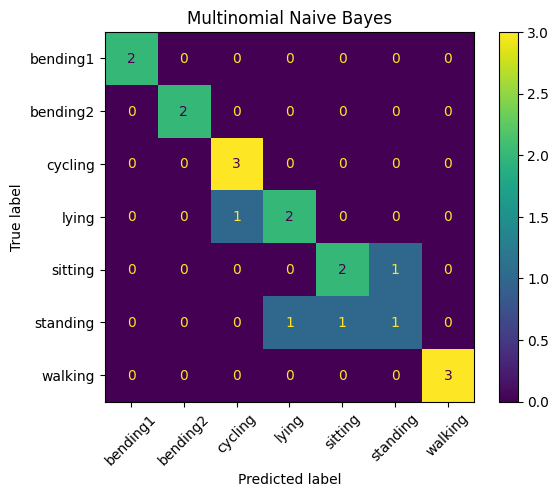

,model,segments,cv_accuracy,test_accuracy
0,Gaussian,1,0.870915,0.894737
1,Multinomial,10,0.855392,0.789474


In [27]:

# Import Naive Bayes libraries
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Store model results
nb_results = []

# Compare Gaussian and Multinomial Naive Bayes
models = {
    'Gaussian': (
        Pipeline([
            ('scale', StandardScaler()),
            ('nb', GaussianNB())
        ]),
        {'nb__var_smoothing': [1e-9, 1e-7, 1e-5]}
    ),
    'Multinomial': (
        Pipeline([
            ('scale', MinMaxScaler()),
            ('nb', MultinomialNB())
        ]),
        {'nb__alpha': [0.01, 0.1, 1, 10]}
    )
}

# Test 1 to 20 time-series segments
for L in range(1, 21):

    # Extract features for this segment count
    X = dataset_for_segments(train_records, L)

    for name, (pipe, params) in models.items():

        # Find best parameters using cross-validation
        search = GridSearchCV(
            pipe,
            params,
            cv=cv_multi,
            scoring='accuracy',
            n_jobs=-1
        )

        search.fit(X, y_multi)

        # Save results
        nb_results.append([
            name,
            L,
            search.best_score_,
            search.best_params_
        ])

    print(f"Finished L={L}/20", flush=True)

# Create comparison table
nb_table = pd.DataFrame(
    nb_results,
    columns=['model', 'segments', 'cv_accuracy', 'parameters']
)

display(
    nb_table.sort_values(
        'cv_accuracy',
        ascending=False
    ).head(12)
)

# Train the best version of each model
nb_fitted = {}
nb_summary = []

for name, (pipe, params) in models.items():

    # Find the best segment count
    best = nb_table[
        nb_table['model'] == name
    ].sort_values(
        ['cv_accuracy', 'segments'],
        ascending=[False, True]
    ).iloc[0]

    L = int(best['segments'])

    # Apply selected parameters
    pipe.set_params(**best['parameters'])

    # Prepare data
    X_train_nb = dataset_for_segments(train_records, L)
    X_test_nb = dataset_for_segments(test_records, L)

    # Train the model
    pipe.fit(X_train_nb, y_multi)

    # Predict test activities
    predictions = pipe.predict(X_test_nb)

    # Calculate accuracy
    test_accuracy = accuracy_score(
        y_multi_test,
        predictions
    )

    nb_fitted[name] = pipe

    nb_summary.append([
        name,
        L,
        best['cv_accuracy'],
        test_accuracy
    ])

    # Display results
    print("\nModel:", name)
    print("Best segments:", L)
    print("CV accuracy:", best['cv_accuracy'])
    print("Test accuracy:", test_accuracy)

    print(classification_report(
        y_multi_test,
        predictions,
        zero_division=0
    ))

    # Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_multi_test,
        predictions,
        xticks_rotation=45
    )

    plt.title(name + " Naive Bayes")
    plt.show()

# Display final Naive Bayes comparison
nb_summary = pd.DataFrame(
    nb_summary,
    columns=['model', 'segments', 'cv_accuracy', 'test_accuracy']
)

display(nb_summary)


#### ii. Comparison

The three multiclass classification models were compared using cross-validation and test accuracy. Multinomial logistic regression achieved 91.34% cross-validation accuracy and 89.47% test accuracy. Gaussian Naive Bayes achieved 87.09% cross-validation accuracy and 89.47% test accuracy. Multinomial Naive Bayes achieved 85.54% cross-validation accuracy and 78.95% test accuracy.

Multinomial logistic regression had the highest cross-validation accuracy, while logistic regression and Gaussian Naive Bayes achieved the same test accuracy. Multinomial Naive Bayes performed less effectively, possibly because the sensor features are continuous measurements rather than count-based data. Overall, multinomial logistic regression performed best based on cross-validation accuracy.

## 3. ISLR 4.8.3


In Quadratic Discriminant Analysis (QDA), each class has its own mean and variance. We assume that the predictor follows a normal distribution:

\[
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
\]

Using Bayes' theorem, the discriminant function is:

\[
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\]

Expanding the squared term gives:

\[
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k x}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k)
\]

This equation contains an \(x^2\) term. Since different classes have different variances, the quadratic terms generally do not cancel when comparing classes.

Therefore, the decision boundary in QDA is generally quadratic rather than linear. This is the main difference between QDA and LDA, which assumes equal variances across classes.

## 4. ISLR 4.8.7


We are given:

- Mean profit for companies paying dividends: 10
- Mean profit for companies not paying dividends: 0
- Variance for both groups: 36
- Probability of paying dividends: 0.80
- Previous year's profit: 4

Using Bayes' theorem:

\[
P(\text{Yes}\mid X=4)=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}
\]

Since both groups follow normal distributions with variance 36:

\[
f_{\text{Yes}}(4)\propto e^{-(4-10)^2/72}=e^{-0.5}
\]

\[
f_{\text{No}}(4)\propto e^{-(4-0)^2/72}=e^{-2/9}
\]

Substituting:

\[
P(\text{Yes}\mid X=4)=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-2/9}}
\]

\[
\boxed{P(\text{Yes}\mid X=4)\approx0.752}
\]

Therefore, the company has approximately a **75.2% probability** of issuing a dividend this year.



## 5.1. Extra Practice ISLR 4.8.4

**(a)** With one feature, we use 10% of the available range.

\[
0.1=10\%
\]

Therefore, approximately 10% of observations are used.

**(b)** With two features, we use 10% of each feature's range.

\[
0.1^2=0.01=1\%
\]

Only 1% of observations are used.

**(c)** With 100 features:

\[
0.1^{100}=10^{-100}
\]

This is an extremely small fraction, practically zero.

**(d)** As the number of features increases, the fraction of observations close to a test observation decreases rapidly. This is called the curse of dimensionality. It makes KNN less effective because very few training observations are nearby.

**(e)** To include 10% of the observations in a \(p\)-dimensional hypercube, the side length \(s\) must satisfy:

\[
s^p=0.1
\]

Therefore:

\[
s=0.1^{1/p}
\]

For \(p=1\):

\[
s=0.1
\]

For \(p=2\):

\[
s=\sqrt{0.1}\approx0.3162
\]

For \(p=100\):

\[
s=0.1^{1/100}\approx0.9772
\]

As the number of dimensions increases, the hypercube must cover almost the entire range of every feature to include 10% of observations. This shows why finding nearby observations becomes difficult in high-dimensional data.

## 5.2. Extra Practice ISLR 4.8.9

**(a)** We are given odds of 0.37 for defaulting on a credit card payment.

The relationship between odds and probability is:

\[
P=\frac{\text{odds}}{1+\text{odds}}
\]

Substituting:

\[
P=\frac{0.37}{1+0.37}
\]

\[
P=\frac{0.37}{1.37}\approx0.2701
\]

Therefore, approximately **27.01%** of people with odds of 0.37 will default.

**(b)** We are given a probability of 16%, or 0.16.

The formula for odds is:

\[
\text{Odds}=\frac{P}{1-P}
\]

Substituting:

\[
\text{Odds}=\frac{0.16}{1-0.16}
\]

\[
\text{Odds}=\frac{0.16}{0.84}\approx0.1905
\]

Therefore, the odds of defaulting are approximately **0.1905**, or **0.1905 to 1**.